# Football Player Valuation & Scouting Model
Predicting transfer market valuations of professional football players using tree-based regression models and tactical skill attributes.


In [1]:
# 1. Imports
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import r2_score, mean_absolute_error, median_absolute_error

import lightgbm as lgb
import xgboost as xgb
import catboost as cb
from sklearn.ensemble import RandomForestRegressor

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("All libraries imported successfully.")


All libraries imported successfully.


## 2. Load Dataset
Loading the FIFA player database with 16,000+ athletes and inspecting the top records.


In [2]:
dataset_path = 'players_22.csv' if os.path.exists('players_22.csv') else 'fifa_players.csv'
print(f"Loading dataset: {dataset_path}")
df_raw = pd.read_csv(dataset_path, low_memory=False)
print(f"Total players: {df_raw.shape[0]:,}")
print(f"Total attributes: {df_raw.shape[1]}")

preview_cols = ['short_name', 'age', 'overall', 'potential', 'player_positions', 'club_name', 'value_eur']
df_raw[preview_cols].sort_values(by='value_eur', ascending=False).head(5)


Loading dataset: players_22.csv


Total players: 19,239
Total attributes: 110


,short_name,age,overall,potential,player_positions,club_name,value_eur
6,K. Mbappé,22,91,95,"ST, LW",Paris Saint-Germain,194000000.0
29,E. Haaland,20,88,93,ST,Borussia Dortmund,137500000.0
9,H. Kane,27,90,90,ST,Tottenham Hotspur,129500000.0
3,Neymar Jr,29,91,91,"LW, CAM",Paris Saint-Germain,129000000.0
4,K. De Bruyne,30,91,91,"CM, CAM",Manchester City,125500000.0


## 3. Data Exploration & Target Distribution
Checking the distribution of player market values (`value_eur`). Because top superstars are valued exponentially higher than squad players, market values are heavily right-skewed. Taking the log transform linearizes the distribution.


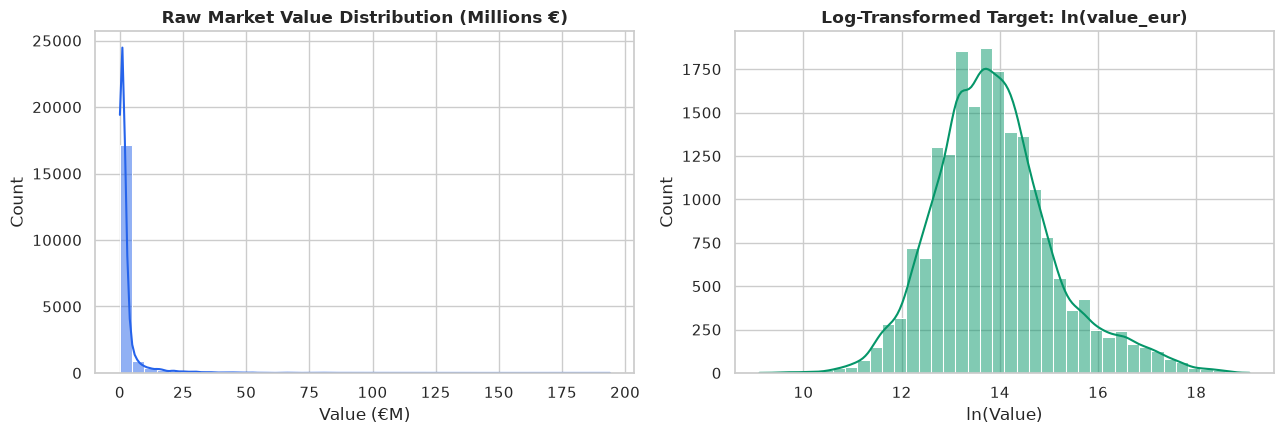

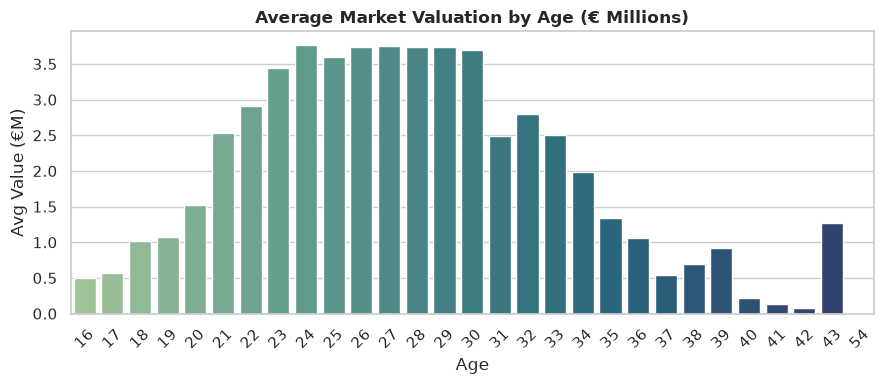

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

valid_vals = df_raw[df_raw['value_eur'] > 1000]['value_eur']

# Raw distribution
sns.histplot(valid_vals / 1e6, bins=40, kde=True, ax=axes[0], color='#2563eb')
axes[0].set_title("Raw Market Value Distribution (Millions €)", fontweight='bold')
axes[0].set_xlabel("Value (€M)")

# Log-transformed distribution
sns.histplot(np.log(valid_vals), bins=40, kde=True, ax=axes[1], color='#059669')
axes[1].set_title("Log-Transformed Target: ln(value_eur)", fontweight='bold')
axes[1].set_xlabel("ln(Value)")

plt.tight_layout()
plt.show()

# Age vs Average Value
plt.figure(figsize=(9, 4))
age_val = df_raw.groupby('age')['value_eur'].mean() / 1e6
sns.barplot(x=age_val.index, y=age_val.values, palette="crest")
plt.title("Average Market Valuation by Age (€ Millions)", fontweight='bold')
plt.xlabel("Age")
plt.ylabel("Avg Value (€M)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 4. Data Cleaning & Feature Engineering
1. Filter out free agents or records with 0 valuation.
2. Group specific detailed roles (`ST`, `CB`, `CM`, `GK`, etc.) into 4 broad tactical categories: `Forward`, `Midfielder`, `Defender`, `Goalkeeper`.
3. Impute missing outfield skills for goalkeepers using physical/power stats.
4. Add engineered features:
   - `potential_growth = potential - overall`
   - `is_in_prime_age` (ages 24–29)
   - `overall_squared` (captures non-linear superstar premium)
   - `technical_rating` (average of shooting, passing, dribbling)
   - `physical_rating` (average of pace and physical)


In [4]:
df = df_raw[df_raw['value_eur'] > 1000].copy()

# Group positions
def get_position_group(pos):
    if pd.isnull(pos):
        return 'Midfielder'
    p = str(pos).split(',')[0].strip()
    if p == 'GK':
        return 'Goalkeeper'
    elif p in ['CB', 'LB', 'RB', 'RWB', 'LWB']:
        return 'Defender'
    elif p in ['CM', 'CDM', 'CAM', 'LM', 'RM']:
        return 'Midfielder'
    else:
        return 'Forward'

df['position_group'] = df['player_positions'].apply(get_position_group)

# Impute goalkeepers' outfield skills
df['pace'] = df['pace'].fillna(df['movement_sprint_speed']).fillna(50)
df['shooting'] = df['shooting'].fillna(df['power_shot_power']).fillna(50)
df['passing'] = df['passing'].fillna(df['skill_long_passing']).fillna(50)
df['dribbling'] = df['dribbling'].fillna(df['skill_ball_control']).fillna(50)
df['defending'] = df['defending'].fillna(df['defending_standing_tackle']).fillna(50)
df['physic'] = df['physic'].fillna(df['power_strength']).fillna(50)

# Feature engineering
df['potential_growth'] = df['potential'] - df['overall']
df['is_in_prime_age'] = ((df['age'] >= 24) & (df['age'] <= 29)).astype(int)
df['overall_squared'] = (df['overall'] / 10.0) ** 2
df['technical_rating'] = (df['shooting'] + df['passing'] + df['dribbling']) / 3.0
df['physical_rating'] = (df['pace'] + df['physic']) / 2.0

df['preferred_foot'] = df['preferred_foot'].fillna('Right')
df['international_reputation'] = df['international_reputation'].fillna(1)
df['weak_foot'] = df['weak_foot'].fillna(3)
df['skill_moves'] = df['skill_moves'].fillna(2)

print(f"Cleaned dataset ready: {df.shape[0]:,} players.")
df[['short_name', 'position_group', 'overall', 'potential_growth', 'is_in_prime_age', 'value_eur']].head()


Cleaned dataset ready: 19,165 players.


,short_name,position_group,overall,potential_growth,is_in_prime_age,value_eur
0,L. Messi,Forward,93,0,0,78000000.0
1,R. Lewandowski,Forward,92,0,0,119500000.0
2,Cristiano Ronaldo,Forward,91,0,0,45000000.0
3,Neymar Jr,Forward,91,0,1,129000000.0
4,K. De Bruyne,Midfielder,91,0,0,125500000.0


## 5. Train-Validation-Test Split
Splitting the dataset into:
- **70% Train** (model training)
- **15% Validation** (hyperparameter tuning)
- **15% Test** (unseen final evaluation)


In [5]:
num_features = [
    'age', 'overall', 'potential', 'potential_growth',
    'international_reputation', 'weak_foot', 'skill_moves',
    'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic',
    'technical_rating', 'physical_rating', 'is_in_prime_age', 'overall_squared'
]
cat_features = ['position_group', 'preferred_foot']

X = df[num_features + cat_features]
y = df['value_eur']
y_log = np.log(y)

X_train_full, X_test, y_train_full_log, y_test_log = train_test_split(
    X, y_log, test_size=0.15, random_state=42
)
X_train, X_val, y_train_log, y_val_log = train_test_split(
    X_train_full, y_train_full_log, test_size=0.1765, random_state=42
)

y_train_orig = np.exp(y_train_log)
y_val_orig = np.exp(y_val_log)
y_test_orig = np.exp(y_test_log)

print(f"Train set:      {X_train.shape[0]:,} players ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Validation set: {X_val.shape[0]:,} players ({X_val.shape[0]/len(df)*100:.1f}%)")
print(f"Test set:       {X_test.shape[0]:,} players ({X_test.shape[0]/len(df)*100:.1f}%)")


Train set:      13,414 players (70.0%)
Validation set: 2,876 players (15.0%)
Test set:       2,875 players (15.0%)


## 6. Preprocessing Pipeline
Building a `ColumnTransformer` with `StandardScaler` for numeric attributes and `OneHotEncoder` for categorical features (`position_group` and `preferred_foot`).


In [6]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

# Fit on training data only to avoid leakage
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

ohe_cols = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_features))
all_feature_names = num_features + ohe_cols
print(f"Preprocessor fitted successfully. Total features: {len(all_feature_names)}")
print("Features:", all_feature_names)


Preprocessor fitted successfully. Total features: 23
Features: ['age', 'overall', 'potential', 'potential_growth', 'international_reputation', 'weak_foot', 'skill_moves', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'technical_rating', 'physical_rating', 'is_in_prime_age', 'overall_squared', 'position_group_Defender', 'position_group_Forward', 'position_group_Goalkeeper', 'position_group_Midfielder', 'preferred_foot_Left', 'preferred_foot_Right']


## 7. Model Training & Comparison
Training 4 baseline regressors on the log target:
- **LightGBM**
- **XGBoost**
- **CatBoost**
- **Random Forest**

Evaluating on the test set with Log R2, Original Scale R2, MAE (€), MedAE (€), and Valuation Accuracy within ±20%.


In [7]:
models = {
    'LightGBM': lgb.LGBMRegressor(n_estimators=300, learning_rate=0.06, num_leaves=63, random_state=42, n_jobs=-1, verbose=-1),
    'XGBoost': xgb.XGBRegressor(n_estimators=300, learning_rate=0.06, max_depth=7, subsample=0.85, colsample_bytree=0.85, random_state=42, n_jobs=-1),
    'CatBoost': cb.CatBoostRegressor(iterations=300, learning_rate=0.06, depth=7, random_state=42, verbose=0),
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=18, random_state=42, n_jobs=-1)
}

benchmark_results = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_proc, y_train_log)
    
    preds_log = model.predict(X_test_proc)
    preds_orig = np.exp(preds_log)
    
    # Calculate metrics
    log_r2 = r2_score(y_test_log, preds_log)
    orig_r2 = r2_score(y_test_orig, preds_orig)
    mae = mean_absolute_error(y_test_orig, preds_orig)
    medae = median_absolute_error(y_test_orig, preds_orig)
    acc_20 = np.mean(np.abs(y_test_orig - preds_orig) / y_test_orig <= 0.20) * 100.0
    
    benchmark_results[name] = {
        'Log R2': round(log_r2, 4),
        'Orig R2': round(orig_r2, 4),
        'MAE (€)': round(mae, 2),
        'MedAE (€)': round(medae, 2),
        'Acc ±20% (%)': round(acc_20, 2)
    }

results_df = pd.DataFrame(benchmark_results).T
print("\nBaseline Model Comparison:")
display(results_df)


Training LightGBM...


Training XGBoost...


Training CatBoost...


Training Random Forest...



Baseline Model Comparison:


,Log R2,Orig R2,MAE (€),MedAE (€),Acc ±20% (%)
LightGBM,0.9989,0.9681,111772.00,14623.57,99.69
XGBoost,0.9988,0.9723,106147.59,14796.81,99.51
CatBoost,0.9986,0.9831,91149.74,17255.63,99.65
Random Forest,0.9980,0.9526,149553.11,12105.57,99.10


## 8. Hyperparameter Tuning (RandomizedSearchCV)
Tuning the top two algorithms (LightGBM and XGBoost) using 3-fold cross validation.


In [8]:
# 1. Tuning LightGBM
print("Tuning LightGBM...")
lgb_grid = {
    'n_estimators': [250, 350, 450],
    'learning_rate': [0.03, 0.05, 0.08],
    'num_leaves': [31, 63, 127],
    'min_child_samples': [20, 40, 80],
    'subsample': [0.8, 0.9, 1.0]
}

lgb_search = RandomizedSearchCV(
    lgb.LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    param_distributions=lgb_grid,
    n_iter=8, cv=3, scoring='r2', random_state=42, n_jobs=-1, verbose=1
)
lgb_search.fit(X_train_proc, y_train_log)
print("Best LightGBM params:", lgb_search.best_params_)

best_lgb = lgb.LGBMRegressor(**lgb_search.best_params_, random_state=42, n_jobs=-1, verbose=-1)
best_lgb.fit(X_train_proc, y_train_log)
preds_lgb_tuned = np.exp(best_lgb.predict(X_test_proc))

# 2. Tuning XGBoost
print("\nTuning XGBoost...")
xgb_grid = {
    'n_estimators': [250, 350, 450],
    'learning_rate': [0.03, 0.05, 0.08],
    'max_depth': [6, 8, 10],
    'subsample': [0.8, 0.9],
    'colsample_bytree': [0.75, 0.85]
}

xgb_search = RandomizedSearchCV(
    xgb.XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions=xgb_grid,
    n_iter=6, cv=3, scoring='r2', random_state=42, n_jobs=-1, verbose=1
)
xgb_search.fit(X_train_proc, y_train_log)
print("Best XGBoost params:", xgb_search.best_params_)

best_xgb = xgb.XGBRegressor(**xgb_search.best_params_, random_state=42, n_jobs=-1)
best_xgb.fit(X_train_proc, y_train_log)
preds_xgb_tuned = np.exp(best_xgb.predict(X_test_proc))

# Summary comparison
tuning_comp = {
    'LightGBM (Base)':  {'Orig R2': benchmark_results['LightGBM']['Orig R2'], 'Acc ±20%': benchmark_results['LightGBM']['Acc ±20% (%)'], 'MAE (€)': benchmark_results['LightGBM']['MAE (€)']},
    'LightGBM (Tuned)': {'Orig R2': round(r2_score(y_test_orig, preds_lgb_tuned), 4), 'Acc ±20%': round(np.mean(np.abs(y_test_orig - preds_lgb_tuned)/y_test_orig <= 0.20)*100, 2), 'MAE (€)': round(mean_absolute_error(y_test_orig, preds_lgb_tuned), 2)},
    'XGBoost (Base)':   {'Orig R2': benchmark_results['XGBoost']['Orig R2'],  'Acc ±20%': benchmark_results['XGBoost']['Acc ±20% (%)'],  'MAE (€)': benchmark_results['XGBoost']['MAE (€)']},
    'XGBoost (Tuned)':  {'Orig R2': round(r2_score(y_test_orig, preds_xgb_tuned), 4), 'Acc ±20%': round(np.mean(np.abs(y_test_orig - preds_xgb_tuned)/y_test_orig <= 0.20)*100, 2), 'MAE (€)': round(mean_absolute_error(y_test_orig, preds_xgb_tuned), 2)}
}

print("\nHyperparameter Tuning Results:")
display(pd.DataFrame(tuning_comp).T)


Tuning LightGBM...
Fitting 3 folds for each of 8 candidates, totalling 24 fits


Best LightGBM params: {'subsample': 0.9, 'num_leaves': 63, 'n_estimators': 350, 'min_child_samples': 20, 'learning_rate': 0.08}



Tuning XGBoost...
Fitting 3 folds for each of 6 candidates, totalling 18 fits


Best XGBoost params: {'subsample': 0.9, 'n_estimators': 450, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.85}



Hyperparameter Tuning Results:


,Orig R2,Acc ±20%,MAE (€)
LightGBM (Base),0.9681,99.69,111772.00
LightGBM (Tuned),0.9687,99.69,109514.72
XGBoost (Base),0.9723,99.51,106147.59
XGBoost (Tuned),0.9689,99.55,110589.60


## 9. Evaluation Plots & Feature Importance
Plotting:
1. Actual vs Predicted player market valuations (in log and original scale).
2. Top 15 most influential features in valuation decisions.


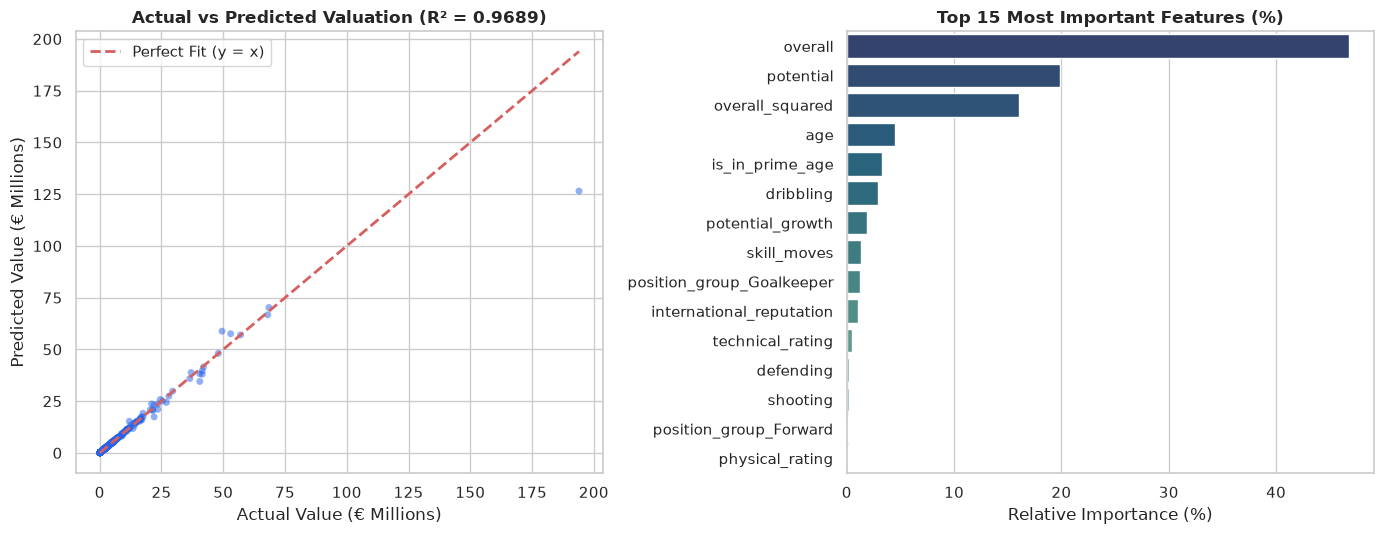

In [9]:
champion = best_xgb

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Actual vs Predicted (Subsample for clean visualization)
np.random.seed(42)
sample_idx = np.random.choice(len(y_test_orig), size=1200, replace=False)
y_sub = y_test_orig.iloc[sample_idx]
pred_sub = preds_xgb_tuned[sample_idx]

axes[0].scatter(y_sub / 1e6, pred_sub / 1e6, alpha=0.5, color='#2563eb', edgecolors='none', s=25)
max_val = max(y_sub.max(), pred_sub.max()) / 1e6
axes[0].plot([0, max_val], [0, max_val], 'r--', lw=2, label='Perfect Fit (y = x)')
axes[0].set_title(f"Actual vs Predicted Valuation (R² = {r2_score(y_test_orig, preds_xgb_tuned):.4f})", fontweight='bold')
axes[0].set_xlabel("Actual Value (€ Millions)")
axes[0].set_ylabel("Predicted Value (€ Millions)")
axes[0].legend()

# Top 15 Feature Importances
importances = champion.feature_importances_
importances = 100.0 * (importances / importances.sum())
feat_series = pd.Series(importances, index=all_feature_names).sort_values(ascending=False).head(15)
clean_labels = [col.replace('cat__', '').replace('num__', '') for col in feat_series.index]

sns.barplot(x=feat_series.values, y=clean_labels, ax=axes[1], palette="crest_r")
axes[1].set_title("Top 15 Most Important Features (%)", fontweight='bold')
axes[1].set_xlabel("Relative Importance (%)")

plt.tight_layout()
plt.show()


## 10. AI Scouting Similarity Engine (Nearest Neighbors)
Building a player similarity engine using cosine distance on scaled technical and physical stats to recommend transfer market alternatives.


In [10]:
scout_cols = ['pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'overall', 'potential']
scout_scaler = StandardScaler()
scout_matrix = scout_scaler.fit_transform(df[scout_cols])

nn_scout = NearestNeighbors(n_neighbors=4, metric='cosine')
nn_scout.fit(scout_matrix)

# Quick demonstration: Find alternatives for Lionel Messi
messi_idx = df[df['short_name'] == 'L. Messi'].index[0]
dists, indices = nn_scout.kneighbors(scout_matrix[messi_idx:messi_idx+1])

print(f"Top 3 Scouting Matches for {df.loc[messi_idx, 'short_name']} (€{df.loc[messi_idx, 'value_eur']:,}):")
for i, neighbor_idx in enumerate(indices[0][1:]):
    sim = (1.0 - dists[0][i+1]) * 100.0
    p = df.iloc[neighbor_idx]
    print(f"  {i+1}. {p['short_name']} ({p['position_group']}, Age {p['age']}) | Overall: {p['overall']} | Value: €{p['value_eur']:,} | Match: {sim:.1f}%")


Top 3 Scouting Matches for L. Messi (€78,000,000.0):
  1. Oyarzabal (Forward, Age 24) | Overall: 85 | Value: €77,500,000.0 | Match: 99.7%
  2. Marco Asensio (Forward, Age 25) | Overall: 83 | Value: €48,000,000.0 | Match: 99.5%
  3. J. Bowen (Midfielder, Age 24) | Overall: 78 | Value: €21,000,000.0 | Match: 99.5%


## 11. Save Models & Production Artifacts
Saving the trained preprocessor, champion model, and scouting similarity engine to disk for the Streamlit web application.


In [11]:
os.makedirs("evaluation_results/saved_models", exist_ok=True)

joblib.dump(champion, "evaluation_results/saved_models/best_footballer_valuation_model.joblib")
joblib.dump(preprocessor, "evaluation_results/saved_models/football_preprocessor.joblib")

joblib.dump({
    'nn_model': nn_scout,
    'scout_scaler': scout_scaler,
    'player_db': df[['short_name', 'age', 'overall', 'potential', 'position_group', 'value_eur', 'wage_eur'] + scout_cols].reset_index(drop=True),
    'scout_cols': scout_cols
}, "evaluation_results/saved_models/scout_similarity_engine.joblib")

print("[SUCCESS] All models and pipeline artifacts serialized successfully.")


[SUCCESS] All models and pipeline artifacts serialized successfully.
